# 06 — Modelling dataset (Week 3, Sprint 2)

Runs `src/data/build_model_dataset.py` on `data/processed/series_full_features.parquet` and checks its output.

**Outputs:** `data/processed/model_dataset.parquet` (one row per minute), `data/processed/model_dataset_meta.json`,
`reports/model_dataset_build.log`, `reports/figures/model_dataset/01_invalid_windows.png`.

**Rules applied** (Meeting 1 decisions): `outage`, maintenance event window `mwin`, unscheduled outage window `uwin`
(29 Mar 11:32–23:59), `dst_gap`, `susp_zero`; util/temp filled with 0 on `no_gpu` minutes. A sample (origin t, horizon h)
is usable only if all 60 input minutes and the target minute are valid (`ok_h{h}`).

**Features:** `mod5`, `hour_sin/cos`, `L24_kW` (causal 24-h mean of valid power), `n_valid_in60`, 1- and 5-minute changes of
the covariates (`d1_*`, `d5_*`). Ramp labels at the forecast origin: `ramp_h{h}` (relative, train p95, main definition),
`ramp99_h{h}` (train p99). Scaling is not applied; train statistics are in the meta file.

| Cell | Content | Needs |
|---|---|---|
| 1 | Setup, paths, versions | — |
| 2 | Run the builder (overwrites the outputs) | 1 |
| 3 | Load; schema, nulls, flag counts, invalid reasons | 1 (+ 2 run once) |
| 4 | Reference checks against notebook 05 v2; unscheduled-outage runs | 3 |
| 5 | Splits, valid minutes, usable samples per horizon | 3 |
| 6 | Ramp thresholds (new vs notebook 05 v2) and ramp rates | 3 |
| 7 | Persistence on pairs and on usable samples | 3 |
| 8 | Independent spot checks and a leakage (truncation) test | 3 |
| 9 | Figure: invalid windows around 29 Mar and the 15 Jul maintenance | 3 |
| 10 | Summary | 4, 8 |

Export the outputs after saving the notebook (Cmd+S): `%run ../src/tools/nb_outputs_to_md.py 06_model_dataset.ipynb`.


In [1]:
# Cell 1: setup, paths, input checks, versions (needed by every cell)
import sys, json, subprocess, platform, shutil
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
SCRIPT = ROOT / "src" / "data" / "build_model_dataset.py"
INP = ROOT / "data" / "processed" / "series_full_features.parquet"
OUT = ROOT / "data" / "processed" / "model_dataset.parquet"
META = ROOT / "data" / "processed" / "model_dataset_meta.json"
LOG = ROOT / "reports" / "model_dataset_build.log"
FIG = ROOT / "reports" / "figures" / "model_dataset"
TMP = ROOT / "data" / "interim" / "_tmp_model_dataset"     # cell 8 only, deleted afterwards
HORIZONS = (1, 5, 15)
SPLITS = ("train", "val", "test")
FIG.mkdir(parents=True, exist_ok=True)

pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

for p in (SCRIPT, INP):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p.relative_to(ROOT)}")
print(f"python {platform.python_version()} | polars {pl.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__}")
print("output exists already:", OUT.exists(), "(cell 2 overwrites it)")


OK      src/data/build_model_dataset.py
OK      data/processed/series_full_features.parquet
python 3.11.16 | polars 1.44.2 | numpy 2.4.6 | matplotlib 3.11.2
output exists already: True (cell 2 overwrites it)


In [2]:
# Cell 2: run build_model_dataset.py (needs cell 1). Overwrites OUT, META and the log file.
cmd = [sys.executable, "-u", str(SCRIPT), "--input", str(INP), "--out", str(OUT), "--meta", str(META)]
res = subprocess.run(cmd, capture_output=True, text=True, cwd=ROOT)
LOG.parent.mkdir(parents=True, exist_ok=True)
LOG.write_text(res.stdout + ("\n--- stderr ---\n" + res.stderr if res.stderr else ""))
print(res.stdout)
if res.stderr:
    print("--- stderr ---\n" + res.stderr)
print("exit code:", res.returncode, "| log:", LOG.relative_to(ROOT))
assert res.returncode == 0, "builder failed; send this output"


[10:06:51] build_model_dataset.py 1.1 (2026-10-08)
[10:06:51] input: /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/data/processed/series_full_features.parquet
[10:06:51] rows 303,840 | 2021-03-04 00:00 .. 2021-09-30 23:59 | step 60 s | columns 20
[10:06:51] maintenance days in input: ['2021-03-18', '2021-04-15', '2021-05-20', '2021-06-17', '2021-07-15', '2021-08-10', '2021-09-16']
[10:06:51] DST gap days: [{'date': '2021-03-14', 'hours': [2]}]
[10:06:51] unscheduled outage runs (outside mwin): 2
[10:06:51]   outage 2021-03-29 12:22 .. 2021-03-29 15:03 (162 min) | first susp_zero 2021-03-29 11:32 | uwin 2021-03-29 11:32 .. 2021-03-29 23:59 (748 min)
[10:06:51]   outage 2021-03-29 15:12 .. 2021-03-29 15:12 (1 min) | first susp_zero 2021-03-29 11:32 | uwin 2021-03-29 11:32 .. 2021-03-29 23:59 (748 min)
[10:06:51] counts: rows 303,840, outage 5,548, mwin 20,580, dst_gap 60, susp_zero 49, no_gpu 585, uwin 748, uwin_removed_from_valid 536, zero_power 585, zero_power_valid

In [3]:
# Cell 3: load the output; schema, nulls, flag counts, reasons for invalid minutes (needs cell 1; cell 2 run once)
md = pl.read_parquet(OUT)
meta = json.loads(META.read_text())
print(f"rows {md.height:,} | columns {md.width} | {OUT.stat().st_size / 2**20:.1f} MiB | built {meta['created_utc']} UTC "
      f"| script {meta['version']}")
print(f"input sha256 {meta['input']['sha256'][:16]}...")
print(pl.DataFrame({"column": md.columns, "dtype": [str(t) for t in md.dtypes],
                    "nulls": [md[c].null_count() for c in md.columns]}))

FLAGS = ["valid", "outage", "mwin", "uwin", "dst_gap", "susp_zero", "no_gpu", "maint_day"]
print("\nflag counts (minutes):")
print(md.select([pl.col(f).sum().alias(f) for f in FLAGS]))
print(f"valid share {md['valid'].mean():.4%}")

# reason for each invalid minute (first matching reason in this order)
reason = (pl.when(pl.col("outage")).then(pl.lit("outage"))
            .when(pl.col("mwin")).then(pl.lit("mwin"))
            .when(pl.col("uwin")).then(pl.lit("uwin"))
            .when(pl.col("dst_gap")).then(pl.lit("dst_gap"))
            .when(pl.col("susp_zero")).then(pl.lit("susp_zero"))
            .when(pl.col("P_kW").is_null()).then(pl.lit("power null"))
            .otherwise(pl.lit("valid")))
print("\ninvalid minutes by first reason (outage > mwin > uwin > dst_gap > susp_zero) and split:")
print(md.with_columns(reason.alias("reason")).pivot(on="split", index="reason", values="valid",
                                                     aggregate_function="len").fill_null(0).sort("reason"))
print("\nzero-power minutes that are valid:", md.filter(pl.col("valid") & (pl.col("P_kW") == 0)).height,
      "(expected 0 after the uwin rule)")
print("valid minutes with P_kW null:", md.filter(pl.col("valid") & pl.col("P_kW").is_null()).height)


rows 303,840 | columns 68 | 45.6 MiB | built 2026-10-09 09:06:52 UTC | script 1.1 (2026-10-08)
input sha256 3c0afe2c9d4fcce2...
shape: (68, 3)
┌────────────────────┬──────────────────────────────────────────┬───────┐
│ column             ┆ dtype                                    ┆ nulls │
│ ---                ┆ ---                                      ┆ ---   │
│ str                ┆ str                                      ┆ i64   │
╞════════════════════╪══════════════════════════════════════════╪═══════╡
│ minute_epoch       ┆ Int64                                    ┆ 0     │
│ minute_local       ┆ Datetime(time_unit='us', time_zone=None) ┆ 0     │
│ split              ┆ String                                   ┆ 0     │
│ P_kW               ┆ Float64                                  ┆ 5548  │
│ valid              ┆ Boolean                                  ┆ 0     │
│ outage             ┆ Boolean                                  ┆ 0     │
│ mwin               ┆ Boolean             

In [4]:
# Cell 4: reference checks against notebook 05 v2, unscheduled-outage runs (needs cell 3)
chk = pl.DataFrame([{"check": c["check"], "expected": str(c["expected"]), "observed": str(c["observed"]),
                     "ok": c["ok"]} for c in meta["checks"]])
print(chk)
CHECKS_OK = bool(chk["ok"].all()) if chk.height else False
print("all reference checks ok:", CHECKS_OK)
print("\nunscheduled outage runs (uwin):")
print(pl.DataFrame(meta["uwin_runs"]) if meta["uwin_runs"] else "none")
c = meta["counts"]
print(f"\nvalid before uwin {c['valid_before_uwin']:,} -> after {c['valid']:,} "
      f"(uwin {c['uwin']} min, of which {c['uwin_removed_from_valid']} were valid before)")
print("maintenance days:", meta["maintenance_days"])
print("DST gap days:", meta["dst_gap_days"])
print("covariate nulls outside outage after fill:", meta["fill"]["covariate_nulls_outside_outage"])


shape: (16, 4)
┌──────────────────────────┬──────────────────┬──────────────────┬──────┐
│ check                    ┆ expected         ┆ observed         ┆ ok   │
│ ---                      ┆ ---              ┆ ---              ┆ ---  │
│ str                      ┆ str              ┆ str              ┆ bool │
╞══════════════════════════╪══════════════════╪══════════════════╪══════╡
│ rows                     ┆ 303840           ┆ 303840           ┆ true │
│ first_minute             ┆ 2021-03-04 00:00 ┆ 2021-03-04 00:00 ┆ true │
│ last_minute              ┆ 2021-09-30 23:59 ┆ 2021-09-30 23:59 ┆ true │
│ outage                   ┆ 5548             ┆ 5548             ┆ true │
│ mwin                     ┆ 20580            ┆ 20580            ┆ true │
│ dst_gap                  ┆ 60               ┆ 60               ┆ true │
│ susp_zero                ┆ 49               ┆ 49               ┆ true │
│ no_gpu                   ┆ 585              ┆ 585              ┆ true │
│ valid_before_uwin    

In [5]:
# Cell 5: splits, valid minutes and usable samples per horizon (needs cell 3)
s = meta["split"]
print(f"val starts {s['val_start']} (i_tr {s['i_tr']:,}) | test starts {s['test_start']} (i_va {s['i_va']:,})")
print(md.group_by("split").agg(pl.len().alias("minutes"), pl.col("valid").sum().alias("valid"),
                               pl.col("minute_local").min().alias("first"), pl.col("minute_local").max().alias("last"),
                               pl.col("P_kW").filter(pl.col("valid")).mean().round(3).alias("mean_kW"),
                               pl.col("P_kW").filter(pl.col("valid")).std().round(3).alias("std_kW"))
        .sort(pl.col("first")))
rows = []
for h in HORIZONS:
    for sp in SPLITS:
        sc = meta["sample_counts"][str(h)][sp]
        rows.append({"h": h, "split": sp, "valid pairs": sc["pairs"], "usable samples (60-min rule)": sc["samples"],
                     "lost by 60-min rule": sc["pairs"] - sc["samples"],
                     "lost share": round(1 - sc["samples"] / sc["pairs"], 5)})
print(pl.DataFrame(rows))
# consistency: counts from the table itself
for h in HORIZONS:
    t = md.filter(pl.col(f"ok_h{h}")).group_by(f"split_h{h}").len().sort(f"split_h{h}", nulls_last=True)
    print(f"h={h}: ok_h by split_h ->", dict(zip(t[f"split_h{h}"].to_list(), t["len"].to_list())),
          "(None = origin before a split boundary with the target after it; not used)")


val starts 2021-07-29 16:48 (i_tr 212,688) | test starts 2021-08-30 08:24 (i_va 258,264)
shape: (3, 7)
┌───────┬─────────┬────────┬─────────────────────┬─────────────────────┬─────────┬────────┐
│ split ┆ minutes ┆ valid  ┆ first               ┆ last                ┆ mean_kW ┆ std_kW │
│ ---   ┆ ---     ┆ ---    ┆ ---                 ┆ ---                 ┆ ---     ┆ ---    │
│ str   ┆ u32     ┆ u32    ┆ datetime[μs]        ┆ datetime[μs]        ┆ f64     ┆ f64    │
╞═══════╪═════════╪════════╪═════════════════════╪═════════════════════╪═════════╪════════╡
│ train ┆ 212688  ┆ 197180 ┆ 2021-03-04 00:00:00 ┆ 2021-07-29 16:47:00 ┆ 26.311  ┆ 9.654  │
│ val   ┆ 45576   ┆ 42636  ┆ 2021-07-29 16:48:00 ┆ 2021-08-30 08:23:00 ┆ 29.505  ┆ 8.725  │
│ test  ┆ 45576   ┆ 42636  ┆ 2021-08-30 08:24:00 ┆ 2021-09-30 23:59:00 ┆ 27.607  ┆ 5.856  │
└───────┴─────────┴────────┴─────────────────────┴─────────────────────┴─────────┴────────┘
shape: (9, 6)
┌─────┬───────┬─────────────┬──────────────────────────

In [6]:
# Cell 6: ramp thresholds (new vs notebook 05 v2) and ramp rates (needs cell 3)
# notebook 05 v2 values were computed before the uwin rule (session 5 handoff, Section 8.6)
OLD = {1: dict(rel_p95=0.0299, rel_p99=0.0577, abs_p95_kW=0.821, abs_p99_kW=1.499),
       5: dict(rel_p95=0.0409, rel_p99=0.0834, abs_p95_kW=1.075, abs_p99_kW=2.157),
       15: dict(rel_p95=0.0580, rel_p99=0.1155, abs_p95_kW=1.525, abs_p99_kW=2.930)}
rows = []
for h in HORIZONS:
    t = meta["thresholds"][str(h)]
    for k in ("rel_p95", "rel_p99", "abs_p95_kW", "abs_p99_kW"):
        rows.append({"h": h, "threshold": k, "new": round(t[k], 4), "nb05_v2": OLD[h][k],
                     "rel_change": round(t[k] / OLD[h][k] - 1, 4),
                     "n_train": t["n_train_rel"] if k.startswith("rel") else t["n_train_abs"]})
print(pl.DataFrame(rows))
rows = []
for h in HORIZONS:
    for sp in SPLITS:
        r = meta["ramp_rates"][str(h)][sp]
        rows.append({"h": h, "split": sp, "pairs with L24": r["n"], "ramps p95": r["n_ramps_p95"],
                     "rate p95": round(r["rate_p95"], 4), "ramps p99": r["n_ramps_p99"], "rate p99": round(r["rate_p99"], 4)})
print(pl.DataFrame(rows))
print("expected rates on train: 0.05 (p95) and 0.01 (p99) by construction")
# ramp rate on usable samples only (what the models are scored on)
rows = []
for h in HORIZONS:
    t = (md.filter(pl.col(f"ok_h{h}") & pl.col(f"ramp_h{h}").is_not_null() & pl.col(f"split_h{h}").is_not_null())
           .group_by(f"split_h{h}").agg(pl.len().alias("n"), pl.col(f"ramp_h{h}").mean().round(4).alias("rate p95"),
                                       pl.col(f"ramp99_h{h}").mean().round(4).alias("rate p99"))
           .rename({f"split_h{h}": "split"}).with_columns(pl.lit(h).alias("h")))
    rows.append(t)
print("\nramp rates on usable samples:")
print(pl.concat(rows).select("h", "split", "n", "rate p95", "rate p99").sort("h", "split"))


shape: (12, 6)
┌─────┬────────────┬────────┬─────────┬────────────┬─────────┐
│ h   ┆ threshold  ┆ new    ┆ nb05_v2 ┆ rel_change ┆ n_train │
│ --- ┆ ---        ┆ ---    ┆ ---     ┆ ---        ┆ ---     │
│ i64 ┆ str        ┆ f64    ┆ f64     ┆ f64        ┆ i64     │
╞═════╪════════════╪════════╪═════════╪════════════╪═════════╡
│ 1   ┆ rel_p95    ┆ 0.0295 ┆ 0.0299  ┆ -0.0119    ┆ 192139  │
│ 1   ┆ rel_p99    ┆ 0.0563 ┆ 0.0577  ┆ -0.0246    ┆ 192139  │
│ 1   ┆ abs_p95_kW ┆ 0.8215 ┆ 0.821   ┆ 0.0006     ┆ 197172  │
│ 1   ┆ abs_p99_kW ┆ 1.4996 ┆ 1.499   ┆ 0.0004     ┆ 197172  │
│ 5   ┆ rel_p95    ┆ 0.0399 ┆ 0.0409  ┆ -0.0252    ┆ 192107  │
│ 5   ┆ rel_p99    ┆ 0.08   ┆ 0.0834  ┆ -0.0402    ┆ 192107  │
│ 5   ┆ abs_p95_kW ┆ 1.0747 ┆ 1.075   ┆ -0.0002    ┆ 197140  │
│ 5   ┆ abs_p99_kW ┆ 2.1545 ┆ 2.157   ┆ -0.0012    ┆ 197140  │
│ 15  ┆ rel_p95    ┆ 0.0568 ┆ 0.058   ┆ -0.0201    ┆ 192027  │
│ 15  ┆ rel_p99    ┆ 0.1095 ┆ 0.1155  ┆ -0.0524    ┆ 192027  │
│ 15  ┆ abs_p95_kW ┆ 1.5216 ┆ 1.525   ┆ 

In [7]:
# Cell 7: persistence on valid pairs (as notebook 05) and on usable samples (reference for the models) (needs cell 3)
REF_TEST = {1: 0.2407, 5: 0.4000, 15: 0.6221}   # notebook 05 v2, test, valid pairs
rows = []
for h in HORIZONS:
    for sp in SPLITS:
        a = meta["persistence_pairs"][str(h)][sp]
        b = meta["persistence_samples"][str(h)][sp]
        rows.append({"h": h, "split": sp, "pairs n": a["n"], "MAE pairs": round(a["MAE"], 4),
                     "RMSE pairs": round(a["RMSE"], 4), "samples n": b["n"], "MAE samples": round(b["MAE"], 4),
                     "RMSE samples": round(b["RMSE"], 4), "nb05 test MAE": REF_TEST[h] if sp == "test" else None})
print(pl.DataFrame(rows))
print("\nh = 1 without mod-0 targets (usable samples):")
print(pl.DataFrame([{"split": sp, **meta["persistence_samples"]["1"][sp + "_no_mod0_target"]} for sp in SPLITS]))


shape: (9, 9)
┌─────┬───────┬─────────┬───────────┬────────────┬───────────┬─────────────┬──────────────┬───────────────┐
│ h   ┆ split ┆ pairs n ┆ MAE pairs ┆ RMSE pairs ┆ samples n ┆ MAE samples ┆ RMSE samples ┆ nb05 test MAE │
│ --- ┆ ---   ┆ ---     ┆ ---       ┆ ---        ┆ ---       ┆ ---         ┆ ---          ┆ ---           │
│ i64 ┆ str   ┆ i64     ┆ f64       ┆ f64        ┆ i64       ┆ f64         ┆ f64          ┆ f64           │
╞═════╪═══════╪═════════╪═══════════╪════════════╪═══════════╪═════════════╪══════════════╪═══════════════╡
│ 1   ┆ train ┆ 197172  ┆ 0.2651    ┆ 0.434      ┆ 196700    ┆ 0.2653      ┆ 0.4341       ┆ null          │
│ 1   ┆ val   ┆ 42634   ┆ 0.2864    ┆ 0.5108     ┆ 42575     ┆ 0.2866      ┆ 0.511        ┆ null          │
│ 1   ┆ test  ┆ 42634   ┆ 0.2407    ┆ 0.3838     ┆ 42575     ┆ 0.2407      ┆ 0.3839       ┆ 0.2407        │
│ 5   ┆ train ┆ 197140  ┆ 0.3523    ┆ 0.6184     ┆ 196668    ┆ 0.3522      ┆ 0.6179       ┆ null          │
│ 5   ┆ val   

In [8]:
# Cell 8: independent spot checks and a leakage (truncation) test (needs cells 1 and 3)
rng = np.random.default_rng(42)
n = md.height
P = md["P_kW"].to_numpy().astype(float)
V = md["valid"].to_numpy()
SPOT = {}

# (a) L24 and n_valid_in60 by brute force at random origins
idx = rng.choice(np.arange(n), 400, replace=False)
L24 = md["L24_kW"].to_numpy().astype(float)
n60 = md["n_valid_in60"].to_numpy()
e_l24, e_n60 = 0.0, 0
for i in idx:
    lo = max(0, i - 1439)
    w = V[lo:i + 1]
    ref = P[lo:i + 1][w].mean() if w.sum() >= 720 else np.nan
    e_l24 = max(e_l24, 0.0 if (np.isnan(ref) and np.isnan(L24[i])) else abs(ref - L24[i]))
    e_n60 += int(V[max(0, i - 59):i + 1].sum() != n60[i])
SPOT["L24 max abs diff"] = e_l24
SPOT["n_valid_in60 mismatches"] = e_n60

# (b) covariate changes
e_d = 0.0
for c in ("gpus_alloc", "util_gpu_mean", "mem_used_sum"):
    x = md[c].to_numpy().astype(float)
    for k in (1, 5):
        d = md[f"d{k}_{c}"].to_numpy().astype(float)
        for i in idx[idx >= k]:
            ref = x[i] - x[i - k] if (V[i] and V[i - k]) else np.nan
            e_d = max(e_d, 0.0 if (np.isnan(ref) and np.isnan(d[i])) else abs(ref - d[i]))
SPOT["d1/d5 max abs diff"] = e_d

# (c) ok, split and ramp labels for every origin (vectorised, independent of the script)
i_tr, i_va = meta["split"]["i_tr"], meta["split"]["i_va"]
ar = np.arange(n)
bad_ok = bad_split = bad_ramp = 0
for h in HORIZONS:
    vf = np.r_[V[h:], np.zeros(h, bool)]
    ok_ref = V & vf & (n60 == 60)
    bad_ok += int((md[f"ok_h{h}"].to_numpy() != ok_ref).sum())
    sp_ref = np.full(n, None, dtype=object)
    sp_ref[ar + h < i_tr] = "train"
    sp_ref[(ar >= i_tr) & (ar + h < i_va)] = "val"
    sp_ref[ar >= i_va] = "test"
    sp_ref[ar + h >= n] = None
    bad_split += int((np.array(md[f"split_h{h}"].to_list(), dtype=object) != sp_ref).sum())
    Pf = np.r_[P[h:], np.full(h, np.nan)]
    rel = np.abs(Pf - P) / L24
    dfn = V & vf & np.isfinite(L24) & (L24 > 0)
    thr = meta["thresholds"][str(h)]["rel_p95"]
    lab = md[f"ramp_h{h}"].to_numpy().astype(float)
    bad_ramp += int((np.isnan(lab) != ~dfn).sum()) + int(((rel[dfn] > thr) != (lab[dfn] == 1)).sum())
    q = np.quantile(rel[dfn & (sp_ref == "train")], 0.95)
    bad_ramp += int(abs(q - thr) > 1e-12)
SPOT["ok_h mismatches"] = bad_ok
SPOT["split_h mismatches"] = bad_split
SPOT["ramp label / threshold mismatches"] = bad_ramp

# (d) leakage test: rebuild on the first K minutes only; causal columns of those minutes must not change
K = int(0.66 * n)
TMP.mkdir(parents=True, exist_ok=True)
pl.read_parquet(INP).sort("minute_epoch").head(K).write_parquet(TMP / "in.parquet")
r = subprocess.run([sys.executable, "-u", str(SCRIPT), "--input", str(TMP / "in.parquet"),
                    "--out", str(TMP / "out.parquet"), "--meta", str(TMP / "meta.json"), "--no-expected"],
                   capture_output=True, text=True, cwd=ROOT)
assert r.returncode == 0, r.stdout + r.stderr
tr = pl.read_parquet(TMP / "out.parquet")
CAUSAL = (["valid", "outage", "mwin", "uwin", "dst_gap", "susp_zero", "no_gpu", "mod5", "hour_sin", "hour_cos",
           "L24_kW", "n_valid_in60"] + [c for c in md.columns if c[:3] in ("d1_", "d5_")])
diff_cols = [c for c in CAUSAL if not tr[c].equals(md[c].head(K))]
SPOT["leakage test: causal columns that changed"] = len(diff_cols)
print(f"truncated at minute {K:,} ({md['minute_local'][K - 1]}); changed columns: {diff_cols if diff_cols else 'none'}")
shutil.rmtree(TMP)

for k, v in SPOT.items():
    print(f"{k:45s} {v}")
SPOT_OK = (SPOT["L24 max abs diff"] < 1e-9 and SPOT["d1/d5 max abs diff"] < 1e-9 and
           all(v == 0 for k, v in SPOT.items() if k not in ("L24 max abs diff", "d1/d5 max abs diff")))
print("all spot checks ok:", SPOT_OK)


truncated at minute 200,534 (2021-07-21 06:13:00); changed columns: none
L24 max abs diff                              2.3248958314070478e-11
n_valid_in60 mismatches                       0
d1/d5 max abs diff                            0.0
ok_h mismatches                               0
split_h mismatches                            0
ramp label / threshold mismatches             0
leakage test: causal columns that changed     0
all spot checks ok: True


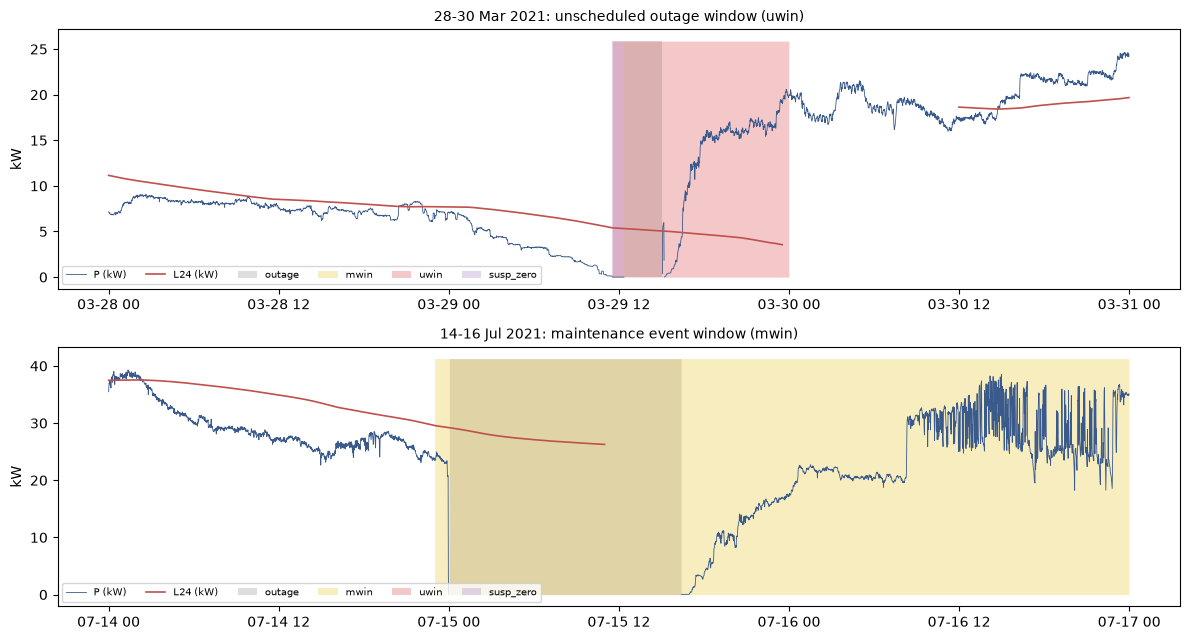

saved reports/figures/model_dataset/01_invalid_windows.png
shape: (9, 8)
┌─────────────────────┬──────────┬────────────┬───────────────┬────────┬───────────┬───────┬───────┐
│ minute_local        ┆ P_kW     ┆ gpus_alloc ┆ n_gpu_streams ┆ outage ┆ susp_zero ┆ uwin  ┆ valid │
│ ---                 ┆ ---      ┆ ---        ┆ ---           ┆ ---    ┆ ---       ┆ ---   ┆ ---   │
│ datetime[μs]        ┆ f64      ┆ i64        ┆ i64           ┆ bool   ┆ bool      ┆ bool  ┆ bool  │
╞═════════════════════╪══════════╪════════════╪═══════════════╪════════╪═══════════╪═══════╪═══════╡
│ 2021-03-29 11:28:00 ┆ 0.119855 ┆ 23         ┆ 2             ┆ false  ┆ false     ┆ false ┆ true  │
│ 2021-03-29 11:29:00 ┆ 0.124455 ┆ 23         ┆ 2             ┆ false  ┆ false     ┆ false ┆ true  │
│ 2021-03-29 11:30:00 ┆ 0.10924  ┆ 22         ┆ 2             ┆ false  ┆ false     ┆ false ┆ true  │
│ 2021-03-29 11:31:00 ┆ 0.072265 ┆ 21         ┆ 1             ┆ false  ┆ false     ┆ false ┆ true  │
│ 2021-03-29 11:32

In [9]:
# Cell 9: invalid windows around the 29 Mar unscheduled outage and the 15 Jul maintenance (needs cells 1 and 3)
def panel(ax, start, end, title):
    d = md.filter((pl.col("minute_local") >= start) & (pl.col("minute_local") < end))
    t = d["minute_local"].to_numpy()
    ax.plot(t, d["P_kW"].to_numpy(), lw=0.6, color="#3a5a8c", label="P (kW)")
    ax.plot(t, d["L24_kW"].to_numpy(), lw=1.2, color="#c0504d", label="L24 (kW)")
    top = np.nanmax(d["P_kW"].to_numpy()) * 1.05 if d["P_kW"].drop_nulls().len() else 1
    for f, col in (("outage", "#7f7f7f"), ("mwin", "#e6b800"), ("uwin", "#d62728"), ("susp_zero", "#9467bd")):
        m = d[f].to_numpy()
        ax.fill_between(t, 0, top, where=m, color=col, alpha=0.25, step="mid", label=f, linewidth=0)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("kW")
    ax.legend(fontsize=7, ncol=6, loc="lower left")

from datetime import datetime
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
panel(axes[0], datetime(2021, 3, 28), datetime(2021, 3, 31), "28-30 Mar 2021: unscheduled outage window (uwin)")
panel(axes[1], datetime(2021, 7, 14), datetime(2021, 7, 17), "14-16 Jul 2021: maintenance event window (mwin)")
fig.tight_layout()
fig.savefig(FIG / "01_invalid_windows.png", dpi=130)
plt.show()
print("saved", (FIG / "01_invalid_windows.png").relative_to(ROOT))
print(md.filter((pl.col("minute_local") >= datetime(2021, 3, 29, 11, 28)) &
                (pl.col("minute_local") <= datetime(2021, 3, 29, 11, 36)))
        .select("minute_local", "P_kW", "gpus_alloc", "n_gpu_streams", "outage", "susp_zero", "uwin", "valid"))


In [10]:
# Cell 10: summary (needs cells 4 and 8)
c = meta["counts"]
print(f"model dataset: {md.height:,} minutes x {md.width} columns | valid {c['valid']:,} ({c['valid'] / md.height:.2%})")
for h in HORIZONS:
    t = meta["thresholds"][str(h)]
    sc = meta["sample_counts"][str(h)]
    ps = meta["persistence_samples"][str(h)]
    print(f"h={h:>2}: usable samples train/val/test {sc['train']['samples']:,} / {sc['val']['samples']:,} / "
          f"{sc['test']['samples']:,} | rel p95 {t['rel_p95']:.4f} | persistence MAE (samples) val "
          f"{ps['val']['MAE']:.4f} test {ps['test']['MAE']:.4f} kW")
print("reference checks ok:", CHECKS_OK, "| spot checks ok:", SPOT_OK)
print("READY for the baselines" if CHECKS_OK and SPOT_OK else "NOT READY: send the outputs")


model dataset: 303,840 minutes x 68 columns | valid 282,452 (92.96%)
h= 1: usable samples train/val/test 196,700 / 42,575 / 42,575 | rel p95 0.0295 | persistence MAE (samples) val 0.2866 test 0.2407 kW
h= 5: usable samples train/val/test 196,668 / 42,567 / 42,567 | rel p95 0.0399 | persistence MAE (samples) val 0.4299 test 0.4000 kW
h=15: usable samples train/val/test 196,588 / 42,547 / 42,547 | rel p95 0.0568 | persistence MAE (samples) val 0.6048 test 0.6221 kW
reference checks ok: True | spot checks ok: True
READY for the baselines


In [11]:
%run ../src/tools/nb_outputs_to_md.py 06_model_dataset.ipynb

written 06_model_dataset_outputs.md | code cells 12 | figures 1 in 06_model_dataset_outputs_figures
